In [1]:
import os

corpus = []      # texts
file_names = []  # file name of every text, in the same order

data_folder = os.path.join(os.getcwd(), "..", "data", "corpus")
for file in sorted(os.listdir(data_folder)):  # sorted: same order on every computer
    with open(os.path.join(data_folder, file), encoding="utf8") as f:
        corpus.append(f.read())
    file_names.append(file)

print(len(corpus), "Texte wurden erfolgreich in den Korpus geladen.")

36 Texte wurden erfolgreich in den Korpus geladen.


In [2]:
import nltk
from nltk.text import Text
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.util import ngrams
from nltk.tokenize import word_tokenize
from collections import Counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
import numpy as np
import spacy
from textstat.textstat import textstatistics
import pyphen
import re

corpus_list = []
#corpus_vec = []
corpus_name = []

def number_words(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    return len(text_words)

def avg_word_len(text):
    text_words = re.findall(r'\b\w+\b', text.lower()) #regex um alle wörter zu finden und Satzzeichenzu entfernen; außerdem lower den Text
    avg_word_len = sum(len(word) for word in text_words) / len(text_words)
    return round(avg_word_len,1)

def number_sentences(text):
    sentences = nltk.sent_tokenize(text) #tokenize in sentences
    return len(sentences)

def avg_sen_len(text):
    avg_sen_len = round(number_words(text) / number_sentences(text),1) #average sentence length
    return avg_sen_len

#Type-Token-Ratio (TTR)
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0 #make set without duplicates and divide with all tokens (incl. duplicates); if list is empty, dont divide with 0 just say, its 0

def punctuations(tokens):
    excl = 0
    quest = 0
    pct = 0
    com = 0
    semic = 0
    colo = 0

    for i in tokens:
        if i == "!":
            excl += 1
        if i == "?":
            quest += 1
        if i == ".":
            pct += 1
        if i == ",":
            com += 1
        if i == ";":
            semic += 1
        if i == ":":
            colo += 1

    erg_excl = excl / len(tokens)
    erg_quest = quest / len(tokens)
    erg_pct = pct / len(tokens)
    erg_com = com / len(tokens)
    erg_semic = semic / len(tokens)
    erg_colo = colo / len(tokens)

    return erg_excl, erg_quest, erg_pct, erg_com, erg_semic, erg_colo

def syllables_count(text, sprache='de_DE'):
    dic = pyphen.Pyphen(lang=sprache)
    worte = text.split()
    #print(worte)
    silben_gesamt = 0
    global syll1
    syll1 = 0
    
    for wort in worte:
        silben = dic.inserted(wort).split('-')
        #print(silben, len(silben))
        if len(silben) == 1:
            syll1 += 1
            #print("Silbe hier:",len(silben),"---->",silben)
        silben_gesamt += len(silben)

    return silben_gesamt

def avg_syllables_per_word(var3):
    #print("Übermittel var3:",var3)
    words = re.findall(r'\b\w+\b', var3.lower())
    avg_syllables = syllables_count(var3) / len(words)
    #print("Silben:",syllables_count(var3))
    #print("Wörter:",len(words))
    return round(avg_syllables, 1)

def flesch_reading_ease_ger(asl, asw):
    
    fre = 180 - asl - (58.5 - asw)
    
    return round(fre,2)

def wiener_sachtext_formel(text):
    syll = 0
    ms = 0 
    sl = 0
    iw = 0
    es = 0
    words6 = 0
    global syll1

    if syllables_count(text) > 3:
        syll += 1
    ms = syll / number_words(text) * 100
    sl = avg_sen_len(text)

    words = re.findall(r'\b\w+\b', text.lower())
    for word in words:
        if len(word) > 5:
            #print("hier:",len(word),"---->",word)
            words6 += 1
    iw = words6 / number_words(text)
    es = syll1 / number_words(text) * 100
    # print("MS:",ms)
    # print("SL:",sl)
    # print("SL:",sl)
    # print("IW:",iw)
    # print("ES:",es)

    # print("syll1:",syll1)
    # print("# Words:",number_words(text))
    #print("Formel: 0.1935 *", ms,"+ 0.1672 *", sl,"+ 0.1297 *", iw,"- 0.0327 *", es," - 0.875")

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf,2)

def ngram_haeufigkeit(text):
    # Kleinbuchstaben & Tokenisierung
    tokens = word_tokenize(text.lower())

    # Bigramme & Trigramme erzeugen
    bigramme = list(ngrams(tokens, 2))
    trigramme = list(ngrams(tokens, 3))

    # Häufigkeiten zählen
    bigram_haeufigkeit = Counter(bigramme)
    trigram_haeufigkeit = Counter(trigramme)

    # Ergebnisse anzeigen
    print(f"Anzahl eindeutiger Bigramme: {len(bigram_haeufigkeit)}")
    print(f"Anzahl eindeutiger Trigramme: {len(trigram_haeufigkeit)}\n")

    print("Top 5 Bigramme:")
    for bigram, count in bigram_haeufigkeit.most_common(5):
        print(f"{bigram} → {count} Mal")

    print("\nTop 5 Trigramme:")
    for trigram, count in trigram_haeufigkeit.most_common(5):
        print(f"{trigram} → {count} Mal")



In [3]:
for text in corpus:

    nltk_text = Text(nltk.word_tokenize(text.lower())) #lower, damit es keine Doppelungen beim zählen später gibt
    #nltk_text_words = word_tokenize(text)
    
    wordcount = number_words(text)
    sentencescount = number_sentences(text)
    print(wordcount,sentencescount)

    avgsenlen = avg_sen_len(text) #average sentence length
    #print(avg_sen_len)
    avgwordlen = avg_word_len(text)
    #print(avg_word_len)
    #print(avgwordlen,avgsenlen)


    ttr_erg = round(ttr(nltk_text),2)
    avg_punct = punctuations(nltk_text)
    
    avg_syll = avg_syllables_per_word(text)
    fre_ger = flesch_reading_ease_ger(avgsenlen, avg_syll)
    wsf = wiener_sachtext_formel(text)
    print(avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg)
    print(ngram_haeufigkeit(text))

    corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, fre_ger, ttr_erg, round(avg_punct[0],3), round(avg_punct[1],3), round(avg_punct[2],3), round(avg_punct[3],3), round(avg_punct[4],3), round(avg_punct[5],3)]) #All Features
    #corpus_list.append([avgwordlen, avgsenlen, avg_syll, wsf, ttr_erg])
    corpus_name.append(nltk_text)

    print("-----------------------------------------------")

#print("Corpuslist:",corpus_list)

33281 2118
5.8 15.7 1.9 0.24 0.22
Anzahl eindeutiger Bigramme: 28450
Anzahl eindeutiger Trigramme: 38070

Top 5 Bigramme:
(',', 'daß') → 218 Mal
('!', '“') → 199 Mal
(',', 'die') → 150 Mal
(',', 'der') → 125 Mal
('.', 'der') → 121 Mal

Top 5 Trigramme:
('!', '“', '„') → 65 Mal
(',', 'daß', 'der') → 46 Mal
('?', '“', '„') → 32 Mal
(',', 'daß', 'die') → 26 Mal
(',', 'daß', 'er') → 13 Mal
None
-----------------------------------------------
46250 3489
5.5 13.3 1.8 -0.28 0.17
Anzahl eindeutiger Bigramme: 35663
Anzahl eindeutiger Trigramme: 50606

Top 5 Bigramme:
('!', '“') → 592 Mal
('“', '„') → 586 Mal
('.', '„') → 301 Mal
('?', '“') → 285 Mal
(',', 'daß') → 259 Mal

Top 5 Trigramme:
('!', '“', '„') → 309 Mal
('?', '“', '„') → 207 Mal
('“', '„', 'ich') → 44 Mal
(',', 'daß', 'der') → 38 Mal
('“', '„', 'ja') → 35 Mal
None
-----------------------------------------------
68271 3834
5.5 17.8 1.8 0.53 0.16
Anzahl eindeutiger Bigramme: 50883
Anzahl eindeutiger Trigramme: 73690

Top 5 Bigramme:
(

# Support Vector Machine

In [4]:
# Load the important packages
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn import svm
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import sklearn.metrics as metrics

colu = ['AverageWordLength', 'AverageSentenceLength', 'AverageSyllables', 'WienerSachtextFormel', 'FRE_Ger', 'TTR', 'Avg !', 'Avg ?', 'Avg .', 'Avg ,', 'Avg ;', 'Avg :']
corp = pd.DataFrame(corpus_list)
corp.columns = colu
corp["Author"] = [name.split("-")[0].capitalize() for name in file_names]
corp

,AverageWordLength,AverageSentenceLength,AverageSyllables,WienerSachtextFormel,FRE_Ger,TTR,Avg !,Avg ?,Avg .,"Avg ,",Avg ;,Avg :,Author
0,5.8,15.7,1.9,0.24,107.7,0.22,0.013,0.003,0.036,0.061,0.005,0.003,Achleitner
1,5.5,13.3,1.8,-0.28,110.0,0.17,0.022,0.007,0.032,0.062,0.001,0.002,Achleitner
2,5.5,17.8,1.8,0.53,105.5,0.16,0.018,0.004,0.024,0.070,0.002,0.004,Achleitner
3,5.3,16.3,1.7,0.14,106.9,0.17,0.017,0.004,0.030,0.066,0.004,0.004,Achleitner
4,5.5,12.7,1.8,-0.32,110.6,0.15,0.032,0.005,0.029,0.062,0.002,0.005,Achleitner
5,5.4,16.4,1.8,0.27,106.9,0.21,0.004,0.002,0.042,0.088,0.000,0.000,Anonymous
6,5.4,13.3,1.8,-0.25,110.0,0.20,0.001,0.003,0.051,0.073,0.000,0.000,Anonymous
7,5.4,14.9,1.8,0.03,108.4,0.20,0.001,0.002,0.049,0.074,0.000,0.000,Anonymous
8,5.4,15.1,1.8,0.07,108.2,0.21,0.001,0.001,0.051,0.072,0.000,0.000,Anonymous
9,5.5,13.6,1.8,-0.18,109.7,0.21,0.001,0.001,0.054,0.073,0.000,0.000,Anonymous


In [5]:
X = corp[colu] # Features
y = corp.Author # Target variable

In [6]:
X2 = X.drop(X.columns[2:], axis=1)
y2 = corp.iloc[:,12]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, random_state=33, test_size=0.2)

clf = svm.SVC(kernel="linear", gamma=1000, C=1000)
clf_fit = clf.fit(X_train, y_train)
clf_fit.score(X_train, y_train)

0.5714285714285714

In [8]:
color_map = {
    1: '#FF0000',   # red
    2: '#0000FF',   # blue
    3: '#008000',   # green
    4: '#FFA500',   # orange
    5: '#800080',   # purple
    6: '#FFFF00',   # yellow
    7: '#FF00FF',   # black
    8: '#000000',   # lime green
    9: '#A2C523',   # magenta
    10: "#48C5FF"   # sky blue
}

df_y2 = pd.DataFrame(y2)
author_color = {"Goethe": 1, "Achleitner": 2, "Schiller": 3, "Anonymous": 4, "Kafka": 7}
df_y2["Color"] = df_y2["Author"].map(author_color)
df_y2['ColorName'] = df_y2['Color'].map(color_map)

from matplotlib.lines import Line2D
custom_legend = [
    Line2D([0], [0], marker='o', color='b', label='Achleitner', markerfacecolor='#0000FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Anonymous', markerfacecolor='#FFA500', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Goethe', markerfacecolor='#FF0000', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Kafka', markerfacecolor='#FF00FF', markersize=10),
    Line2D([0], [0], marker='o', color='b', label='Schiller', markerfacecolor='#008000', markersize=10)
]

c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


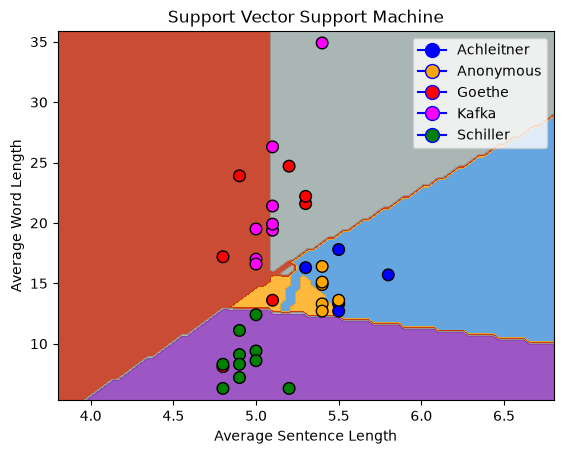

In [9]:
# Plot Decision Boundary
DecisionBoundaryDisplay.from_estimator(
        clf_fit,
        X2,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.8,
        xlabel=X2.columns[0],
        ylabel=X2.columns[1],
    )

# Scatter plot
#plt.figure(figsize=(10,26))
plt.title('Support Vector Support Machine')
plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], 
            c=df_y2['ColorName'], 
            s=70, edgecolors="k")
plt.legend(handles=custom_legend)
plt.xlabel("Average Sentence Length")
plt.ylabel("Average Word Length")
#plt.colorbar()
plt.show()

In [10]:
y_pred = clf_fit.predict(X_test)

In [11]:
accuracy = metrics.accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

Accuracy: 37.50%


In [12]:

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

  Achleitner       0.00      0.00      0.00         0
   Anonymous       0.00      0.00      0.00         2
      Goethe       0.00      0.00      0.00         1
       Kafka       0.00      0.00      0.00         2
    Schiller       1.00      1.00      1.00         3

    accuracy                           0.38         8
   macro avg       0.20      0.20      0.20         8
weighted avg       0.38      0.38      0.38         8



c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\workspace\german-authorship-attribution\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.

### 10 Fold Cross Valdidation

In [13]:
k_folds = KFold(n_splits = 10)

scores = cross_val_score(clf_fit, X2, y2, cv = k_folds)

print("Cross Validation Scores: ", scores)
print("\nAverage CV Score: ", scores.mean())
print("\nNumber of CV Scores used in Average: ", len(scores))

Cross Validation Scores:  [0.25       0.5        0.25       0.         0.         0.
 0.33333333 1.         1.         0.33333333]

Average CV Score:  0.36666666666666664

Number of CV Scores used in Average:  10


## Confusion Matrix

In [14]:
confusion_matrix(y_test, y_pred)

array([[0, 0, 0, 0, 0],
       [2, 0, 0, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 2, 0, 0],
       [0, 0, 0, 0, 3]])

In [15]:
df_cm = pd.DataFrame()
df_cm["True"] = y_test
df_cm["Predict"] = y_pred
df_cm

,True,Predict
17,Goethe,Kafka
8,Anonymous,Achleitner
32,Schiller,Schiller
5,Anonymous,Achleitner
21,Kafka,Goethe
22,Kafka,Goethe
31,Schiller,Schiller
30,Schiller,Schiller


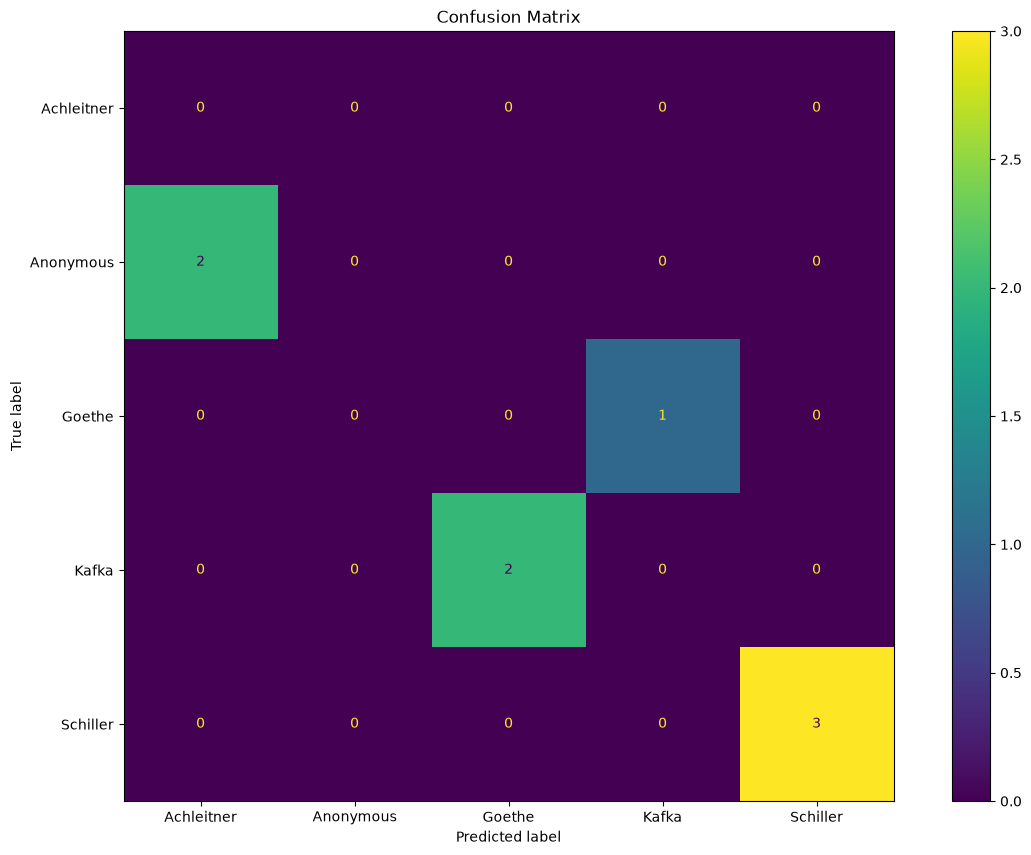

In [16]:
labels = sorted(y.unique())  # all five authors, alphabetical
cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp = cm_display.plot()
disp.figure_.set_size_inches(15, 10)
plt.title("Confusion Matrix")
plt.show()